# Where the drift is heading: the year-3 factor from the free-running E3SMv3 large ensemble

Sixth notebook of `nov2026_outlook/`. Year 3 of the 1 Nov 2026 start (leads 24-35) has no hindcasts to measure
its drift, so it is extended by the rule $d_3(m) = d_2(m) + r\,[d_2(m) - d_1(m)]$ (`01`). $r = 1$ keeps the
forecast continuous at Nov 2028 (`05`), but the 6-month test of `04` suggested $r \approx 0.2$. This notebook
constrains $r$ with the model's own long-lead limit.

**The idea.** A hindcast forgets its initial state, so with lead its ensemble mean tends to the forced
climate of the free-running model under the same forcing: the ensemble mean of the E3SMv3 LR historical large
ensemble (`v3.LR.historical_*`, 25 members, the same ne30pg2/IcoswISC30E3r5 configuration as the hindcasts).
The **gap** between the two at the same target month,

$$G_j(L) = \overline{\mathrm{LE}}(\text{target of } j, L) - \overline{\mathrm{HC}}_j(L),$$

averaged over the start years $j$, is the part of the drift still to come; the observations cancel out of it.
If the hindcast relaxes to the forced climate exponentially, $G(L) = G_0\,e^{-L/T}$, then
$d_2 - d_1 = G_1 - G_2$, $d_3 - d_2 = G_2 - G_3$ and the year-3 factor is exactly

$$r = \frac{G(L+12)}{G(L)} = e^{-12/T},$$

measured from leads 3-11 and 15-23 (after the initial adjustment); $r < 1$ means the drift is levelling off
towards the model's own climate, so $r = 1$ would overshoot it. If instead the gap grows ($r > 1$), the
hindcasts are moving away from the free-running climate over these two years: the drift is still building
and the limit gives no ceiling for year 3.

**What this notebook shows.**
1. Drift, the long-lead limit (LE − observed) and the gap by lead (Nov and May starts).
2. $r$ from the gap, with bootstrap intervals, and the year-3 drift each $r$ implies against the limit.
3. Whether the drift trend behind TrDC (`05`) is the model's forced trend: the LE's Niño3.4 trend against
   the observed one and the spread of single LE members (internal variability).
4. The 1 Nov 2026 outlook (TrDC held at 2018) with the year-3 $r$ from the gap.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/06_year3_drift_asymptote"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/06_year3_drift_asymptote/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR, INIT = 2026, 11
NLEAD_REF = rc.NLEAD
NLEAD = rc.start_nlead(YEAR, INIT)
INITS = (2, 5, 8, 11)                       # start months of the member cache (04); this notebook uses May and Nov
GAP_INITS = (11, 5)
INIT_NAME = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}
REF_YEARS = (1981, 2018)
BASES = {"1981-2010": (1981, 2010), "1991-2018": (1991, 2018), "1981-2018": (1981, 2018)}
OBS_BASE = (1991, 2020)
ADJUST_LEADS = 3
LE_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data/E3SMv3")
LE_GLOB = "v3.LR.historical_*"              # free-running large ensemble (historical, extended to 2049 in the archive)
LE_YEARS = (1980, 2034)                     # years read (5-year files)
TREND_YEARS = (1981, 2020)                  # observed vs forced Niño3.4 trend (the verification years of the starts)
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)
OBS_PRODUCT = "HadISST1.1"
THRESHOLD = -0.5
WINTERS = {"2026/27": 1, "2027/28": 13, "2028/29": 25}
N_BOOT = 2000

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: hindcast members (the cache of `04`) and the large ensemble (cached)

The large ensemble: CMOR `ts` (surface temperature, as the hindcasts' `TS`) on the same 1° grid, Niño3.4 and
the 20°S-20°N ocean mean (EAM land fraction < 0.5, as the hindcasts) of every member, 1980-2034, in °C. Built
once (a few minutes) under `S2D_DIAG_ROOT/RTENSO2026_pool/nino_drift/`.

In [3]:
%%time
CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                    f"nino34_trop_members_init{''.join(f'{m:02d}' for m in INITS)}_ref{REF_YEARS[0]}-{REF_YEARS[1]}"
                    f"_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
NOV_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                        f"nino34_trop_members_init{INIT:02d}_ref{REF_YEARS[0]}-{REF_YEARS[1]}_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
NOV_EXPECTED = {"ref_years": f"{REF_YEARS[0]}-{REF_YEARS[1]}", "year": YEAR, "init": INIT, "nlead": NLEAD,
                "pool": ",".join(POOL), "obs": OBS_PRODUCT}
EXPECTED = {**NOV_EXPECTED, "inits": ",".join(map(str, INITS))}
YEARS = np.arange(REF_YEARS[0], REF_YEARS[1] + 1)


def valid(path, expected):
    return path.is_file() and all(str(load_netcdf(path).attrs.get(k)) == str(v) for k, v in expected.items())


def build():
    ocean = rc.land_fraction() < 0.5
    idx = lambda da: (rc.box_mean(da, NINO_BOX).load(), rc.box_mean(da.where(ocean), TROPICAL_BOX).load())
    rn = np.full((len(INITS), YEARS.size, rc.NENS, NLEAD_REF), np.nan)
    rt = rn.copy()
    nov = load_netcdf(NOV_CACHE) if derivation_mode != "rebuild" and valid(NOV_CACHE, NOV_EXPECTED) else None
    for i, init in enumerate(INITS):
        if init == INIT and nov is not None:
            rn[i], rt[i] = nov["ref_nino"].sel(year=YEARS).values, nov["ref_trop"].sel(year=YEARS).values
            continue
        for k, y in enumerate(YEARS):
            if rc.member_file(rc.REFERENCE["case_prefix"], int(y), init, 0, "TS") is None:
                continue
            ens = rc.open_hindcast(rc.REFERENCE["case_prefix"], int(y), init, "TS")
            if ens is None:
                continue
            n, t = idx(ens)
            rn[i, k, ens["member"].values], rt[i, k, ens["member"].values] = n.values, t.values
    if nov is not None:
        fc = {v: nov[v].values for v in ("fc_nino", "fc_trop", "obs_nino", "obs_trop")}
        members, times = nov["member"].values, nov["time"].values
    else:
        fn, ft, members = [], [], []
        for name, prefix in POOL.items():
            ens = rc.open_hindcast(prefix, YEAR, INIT, "TS")
            n, t = idx(ens)
            fn.append(n.values), ft.append(t.values)
            members += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
        obs = rc.obs_monthly("TS", years=(REF_YEARS[0], YEAR), mode=derivation_mode, product=OBS_PRODUCT)
        on, ot = idx(obs)
        fc = {"fc_nino": np.concatenate(fn), "fc_trop": np.concatenate(ft), "obs_nino": on.values, "obs_trop": ot.values}
        times = [f"{t.year:04d}-{t.month:02d}" for t in obs["time"].to_index()]
    ds = xr.Dataset(
        {"ref_nino": (("init", "year", "ens", "lead"), rn), "ref_trop": (("init", "year", "ens", "lead"), rt),
         "fc_nino": (("member", "flead"), fc["fc_nino"]), "fc_trop": (("member", "flead"), fc["fc_trop"]),
         "obs_nino": ("time", fc["obs_nino"]), "obs_trop": ("time", fc["obs_trop"])},
        coords={"init": list(INITS), "year": YEARS, "ens": np.arange(rc.NENS), "lead": np.arange(NLEAD_REF),
                "member": members, "flead": np.arange(NLEAD), "time": times})
    ds.attrs.update(EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and valid(CACHE, EXPECTED):
    D = load_netcdf(CACHE)
else:
    D = build()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(D, CACHE)
AVAIL = {init: YEARS[np.isfinite(D["ref_nino"].sel(init=init).values).any(axis=(1, 2))] for init in INITS}
for init in INITS:
    print(f"{INIT_NAME[init]}: {AVAIL[init].size} starts ({AVAIL[init][0]}-{AVAIL[init][-1]})")
print(f"{D.sizes['member']} forecast members; HadISST {str(D.time.values[0])} to {str(D.time.values[-1])}")

Feb: 7 starts (1985-2015)
May: 38 starts (1981-2018)
Aug: 7 starts (1985-2015)
Nov: 38 starts (1981-2018)
30 forecast members; HadISST 1981-01 to 2026-09
CPU times: user 773 ms, sys: 279 ms, total: 1.05 s
Wall time: 1.07 s


In [4]:
%%time
LE_DIRS = sorted(LE_ROOT.glob(LE_GLOB))
LE_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                       f"nino34_trop_v3LR_historical_m{len(LE_DIRS)}_y{LE_YEARS[0]}-{LE_YEARS[1]}_v1.nc")
LE_EXPECTED = {"members": ",".join(p.name for p in LE_DIRS), "years": f"{LE_YEARS[0]}-{LE_YEARS[1]}"}


def le_files(run):
    files = sorted((run / "post" / "atm" / "180x360_aave" / "cmip_ts" / "monthly").glob("ts_Amon_*_gr_*.nc"))
    return [f for f in files if LE_YEARS[0] <= int(f.stem.split("_")[-1][:4]) <= LE_YEARS[1]]


def build_le():
    land = rc.land_fraction()
    n_all, t_all, times = [], [], None
    for run in LE_DIRS:
        n_m, t_m, tt = [], [], []
        for f in le_files(run):
            with xr.open_dataset(f, use_cftime=True) as ds:
                ts = ds["ts"].load() - 273.15
            assert np.allclose(ts["lat"], land["lat"]) and np.allclose(ts["lon"], land["lon"])
            ocean = xr.DataArray(land.values < 0.5, coords={"lat": ts["lat"], "lon": ts["lon"]}, dims=("lat", "lon"))
            n_m.append(rc.box_mean(ts, NINO_BOX).values)
            t_m.append(rc.box_mean(ts.where(ocean), TROPICAL_BOX).values)
            tt += [f"{t.year:04d}-{t.month:02d}" for t in ts["time"].values]
        if times is None:
            times = tt
        assert tt == times, run
        n_all.append(np.concatenate(n_m)), t_all.append(np.concatenate(t_m))
    ds = xr.Dataset({"le_nino": (("run", "time"), np.array(n_all)), "le_trop": (("run", "time"), np.array(t_all))},
                    coords={"run": [p.name for p in LE_DIRS], "time": times})
    ds.attrs.update(LE_EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and valid(LE_CACHE, LE_EXPECTED):
    LE = load_netcdf(LE_CACHE)
else:
    LE = build_le()
    atomic_to_netcdf(LE, LE_CACHE)
print(f"large ensemble: {LE.sizes['run']} members, {str(LE.time.values[0])} to {str(LE.time.values[-1])}")

large ensemble: 25 members, 1980-01 to 2034-12
CPU times: user 18.6 ms, sys: 561 μs, total: 19.2 ms
Wall time: 18.3 ms


### Helpers

`kind` "Nino3.4" or "Relative" (Niño3.4 minus the tropical mean, not rescaled). Per start: hindcast
ensemble mean, observed and LE ensemble mean at the target months; drift $d$ = HC − obs, limit
$B$ = LE − obs, gap $G = B - d$ = LE − HC.

In [5]:
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)
LE_IDX = pd.PeriodIndex(LE["time"].values, freq="M")
LE_N = pd.DataFrame(LE["le_nino"].values.T, index=LE_IDX)          # (month, run)
LE_T = pd.DataFrame(LE["le_trop"].values.T, index=LE_IDX)


def target(y, init, lead):
    return pd.Period(year=int(y), month=int(init), freq="M") + int(lead)


def series(kind):
    # hindcast members (init, year, ens, lead), forecast members (member, lead), obs, LE members (month, run)
    if kind == "Nino3.4":
        return D["ref_nino"].values, D["fc_nino"].values, OBS, LE_N
    return (D["ref_nino"] - D["ref_trop"]).values, (D["fc_nino"] - D["fc_trop"]).values, OBS - OBS_T, LE_N - LE_T


def at(s, init, years, nlead):
    return np.array([[s.get(target(y, init, L), np.nan) for L in range(nlead)] for y in years])


def parts(kind, init, starts, nlead=NLEAD):
    # years; hindcast mean (year, 24); obs and LE mean (year, nlead)
    ref, _, obs, le = series(kind)
    years = AVAIL[init][(AVAIL[init] >= starts[0]) & (AVAIL[init] <= starts[1])]
    hc = np.nanmean(ref[INITS.index(init)][np.searchsorted(YEARS, years)], axis=1)
    return years, hc, at(obs, init, years, nlead), at(le.mean(axis=1), init, years, nlead)


def fit_r(g1, g2):
    # least-squares ratio g2 = r g1 over the months after the initial adjustment
    return float(g1 @ g2 / (g1 @ g1))


def extend(c, nlead, r):
    delta = c[12:24] - c[:12]
    delta = np.where(np.arange(12) < ADJUST_LEADS, delta[ADJUST_LEADS:].mean(), delta)
    return np.r_[c[:NLEAD_REF], c[12:24] + r * delta][:nlead]


def djf(a, first):
    return a[..., first:first + 3].mean(-1)

### 1. Drift, long-lead limit and gap by lead

Top: drift $d(L)$ of the hindcasts (leads 0-23), the limit $B(L)$ = LE − observed at the same target months
(leads 0-35; year 3 still has observations for these start years), and year 3 of the drift by the rule with
$r$ = 0, 1 and the $r$ fitted to the gap. Bottom: the gap $G(L)$ = LE − HC, with the fitted
$G(L+12) = r\,G(L)$. Shading: 90% bootstrap over start years.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/06_year3_drift_asymptote/figures/fig_year3_drift_limit_gap.png


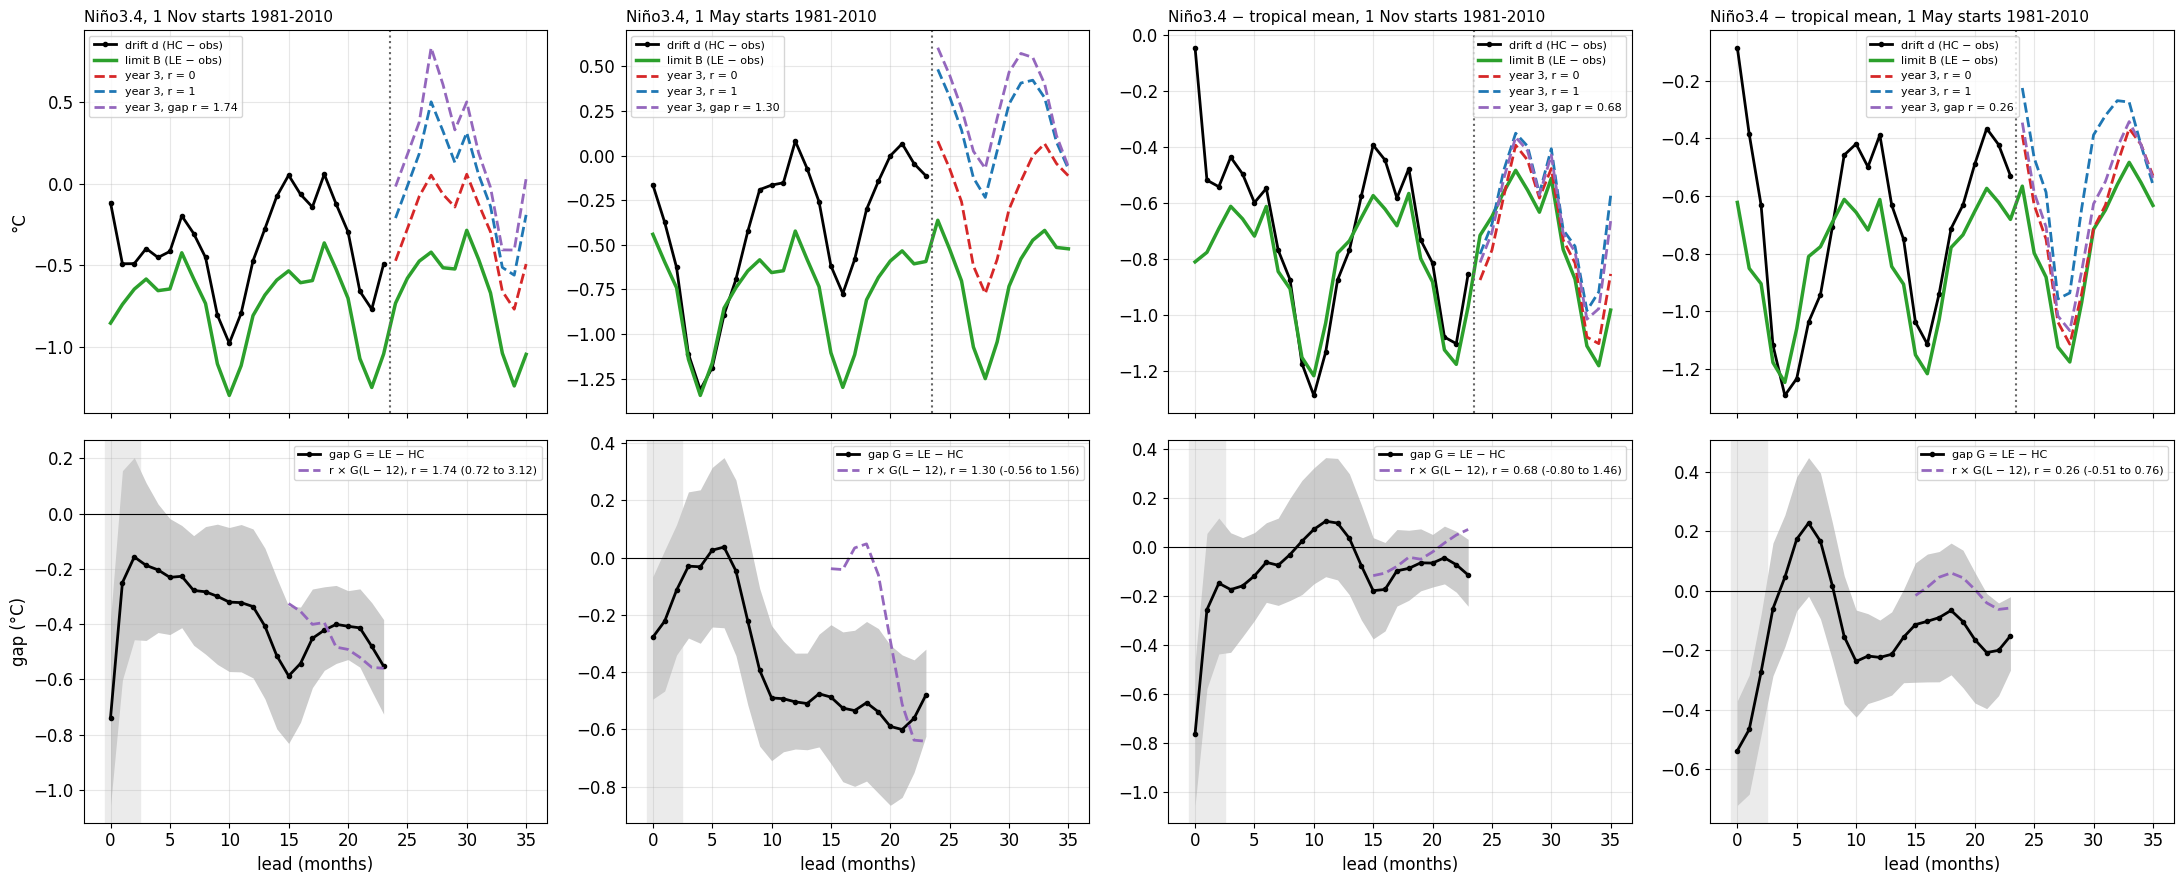

,index,start,base,gap year 1 (°C),gap year 2,r = G2/G1,r 90%,drift year 1,drift year 2,limit B year 2,limit B year 3,"drift year 3, r = 0","drift year 3, r = 1","drift year 3, gap r"
0,Nino3.4,Nov,1981-2010 (30),-0.26,-0.47,1.74,0.72 to 3.12,-0.53,-0.27,-0.73,-0.67,-0.27,-0.01,0.18
1,Nino3.4,Nov,1991-2018 (28),-0.31,-0.60,1.71,0.82 to 2.93,-0.36,0.01,-0.60,-0.54,0.01,0.36,0.61
2,Nino3.4,Nov,1981-2018 (38),-0.33,-0.60,1.62,0.96 to 2.66,-0.43,-0.10,-0.71,-0.64,-0.10,0.22,0.42
3,Nino3.4,May,1981-2010 (30),-0.18,-0.54,1.30,-0.56 to 1.56,-0.68,-0.23,-0.76,-0.68,-0.23,0.17,0.29
4,Nino3.4,May,1991-2018 (28),-0.38,-0.60,1.25,0.48 to 1.65,-0.35,-0.03,-0.62,-0.56,-0.03,0.24,0.31
5,Nino3.4,May,1981-2018 (38),-0.27,-0.67,1.52,0.45 to 1.73,-0.54,-0.09,-0.74,-0.66,-0.09,0.31,0.52
6,Relative,Nov,1981-2010 (30),-0.05,-0.10,0.68,-0.80 to 1.46,-0.81,-0.73,-0.80,-0.75,-0.73,-0.63,-0.66
7,Relative,Nov,1991-2018 (28),-0.12,-0.23,1.84,-0.90 to 2.62,-0.67,-0.50,-0.72,-0.68,-0.50,-0.35,-0.22
8,Relative,Nov,1981-2018 (38),-0.13,-0.22,1.63,-0.41 to 2.42,-0.72,-0.59,-0.79,-0.75,-0.59,-0.45,-0.37
9,Relative,May,1981-2010 (30),-0.00,-0.13,0.26,-0.51 to 0.76,-0.86,-0.67,-0.82,-0.76,-0.67,-0.50,-0.62


In [6]:
rng = np.random.default_rng(0)
rows, RFIT = [], {}
fig, axes = plt.subplots(2, 4, figsize=(22, 9), sharex=True)
for col, (kind, init) in enumerate([(k, i) for k in ("Nino3.4", "Relative") for i in GAP_INITS]):
    for bname, base in BASES.items():
        years, hc, ob, le = parts(kind, init, base)
        d, B = np.nanmean(hc - ob[:, :NLEAD_REF], 0), np.nanmean(le - ob, 0)
        G = np.nanmean(le[:, :NLEAD_REF] - hc, 0)
        sl1, sl2 = slice(ADJUST_LEADS, 12), slice(12 + ADJUST_LEADS, 24)
        r = fit_r(G[sl1], G[sl2])
        boot = []
        for _ in range(N_BOOT):
            k = rng.integers(0, years.size, years.size)
            Gb = np.nanmean(le[k, :NLEAD_REF] - hc[k], 0)
            boot.append(fit_r(Gb[sl1], Gb[sl2]))
        lo, hi = np.percentile(boot, [5, 95])
        RFIT[(kind, init, bname)] = (r, lo, hi)
        d3 = {"r = 0": extend(d, NLEAD, 0.0)[24:], "r = 1": extend(d, NLEAD, 1.0)[24:], f"gap r = {r:.2f}": extend(d, NLEAD, r)[24:]}
        rows.append({"index": kind, "start": INIT_NAME[init], "base": f"{bname} ({years.size})",
                     "gap year 1 (°C)": round(G[sl1].mean(), 2), "gap year 2": round(G[sl2].mean(), 2),
                     "r = G2/G1": round(r, 2), "r 90%": f"{lo:.2f} to {hi:.2f}",
                     "drift year 1": round(d[ADJUST_LEADS:12].mean(), 2), "drift year 2": round(d[12:].mean(), 2),
                     "limit B year 2": round(B[12:24].mean(), 2), "limit B year 3": round(B[24:].mean(), 2),
                     "drift year 3, r = 0": round(d3["r = 0"].mean(), 2), "drift year 3, r = 1": round(d3["r = 1"].mean(), 2),
                     "drift year 3, gap r": round(d3[f"gap r = {r:.2f}"].mean(), 2)})
        if bname != "1981-2010":
            continue
        ax = axes[0, col]
        ax.plot(range(NLEAD_REF), d, "k-o", ms=3, lw=2, label="drift d (HC − obs)")
        ax.plot(range(NLEAD), B, color="tab:green", lw=2.5, label="limit B (LE − obs)")
        for (lab, v), c in zip(d3.items(), ["tab:red", "tab:blue", "tab:purple"]):
            ax.plot(range(24, NLEAD), v, color=c, lw=2, ls="--", label=f"year 3, {lab}")
        ax.axvline(NLEAD_REF - 0.5, color="0.4", ls=":")
        ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 − tropical mean'}, 1 {INIT_NAME[init]} starts {bname}",
                     loc="left", fontsize=11)
        ax.legend(fontsize=8)
        ax = axes[1, col]
        Gb = np.array([np.nanmean(le[k, :NLEAD_REF] - hc[k], 0) for k in rng.integers(0, years.size, (500, years.size))])
        ax.fill_between(range(NLEAD_REF), *np.percentile(Gb, [5, 95], axis=0), color="0.8", lw=0)
        ax.plot(range(NLEAD_REF), G, "k-o", ms=3, lw=2, label="gap G = LE − HC")
        ax.plot(range(12 + ADJUST_LEADS, 24), r * G[sl1], color="tab:purple", lw=2, ls="--",
                label=f"r × G(L − 12), r = {r:.2f} ({lo:.2f} to {hi:.2f})")
        ax.axhline(0, color="k", lw=0.8)
        ax.axvspan(-0.5, ADJUST_LEADS - 0.5, color="0.92", zorder=0)
        ax.set_xlabel("lead (months)")
        ax.legend(fontsize=8)
axes[0, 0].set_ylabel("°C")
axes[1, 0].set_ylabel("gap (°C)")
fig.tight_layout()
save(fig, "year3", "drift_limit_gap")
plt.show()
gap = pd.DataFrame(rows)
gap.to_csv(DATA_DIR / "year3_gap_r.csv", index=False)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(gap)

### 2. Is the drift trend the model's forced trend?

TrDC (`05`) corrects a drift that grows by about +0.3-0.4 °C/decade over the start years, with an observed
Niño3.4 trend near zero. If that is the model's forced warming of the equatorial Pacific, the LE ensemble mean
should show it, and the hindcast drift trend should approach $\beta_{LE} - \beta_{obs}$ with lead. The spread of
the single-member trends is what internal (e.g. decadal Pacific) variability alone gives: where the observed
trend falls in it tells whether the observations can be a realisation of the model's forced climate.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/06_year3_drift_asymptote/figures/fig_drift_trend_forced_vs_observed_trend.png


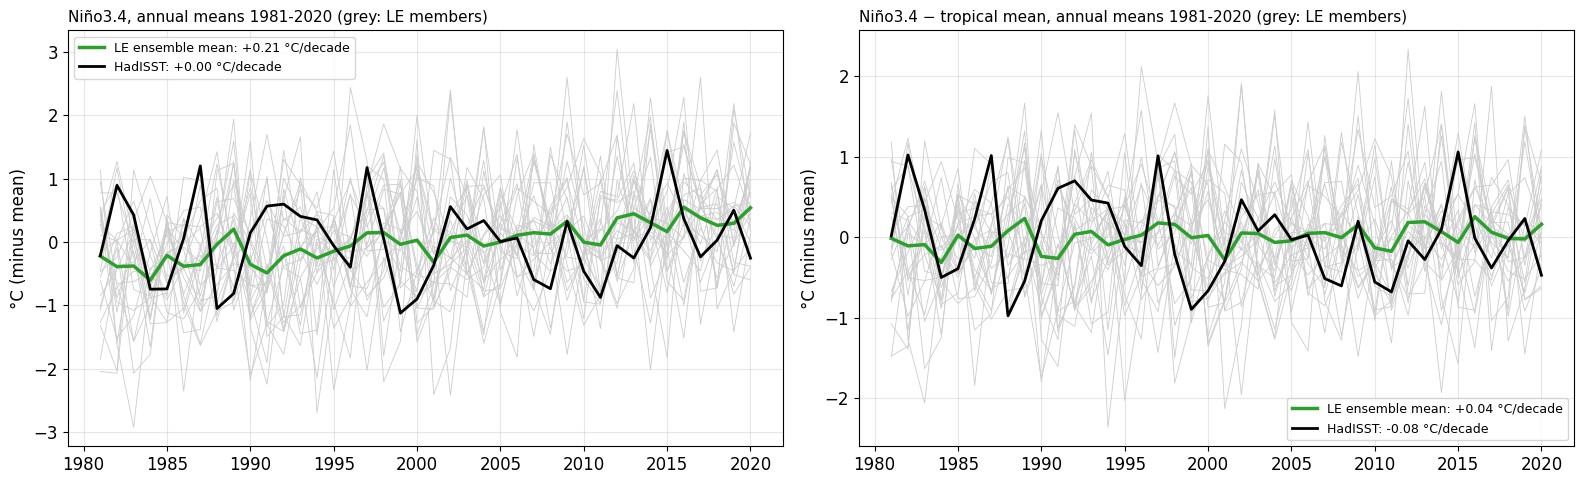

,index,β LE (°C/decade),β obs,β LE − β obs,LE members 5-95%,members with a trend ≤ obs,"drift trend, Nov yr 1","drift trend, Nov yr 2","drift trend, May yr 1","drift trend, May yr 2",β LE 2018-2029
0,Nino3.4,0.21,0.00,0.20,+0.08 to +0.33,0/25,0.28,0.39,0.41,0.35,0.26
1,Relative,0.04,-0.08,0.13,-0.06 to +0.13,0/25,0.22,0.29,0.31,0.25,-0.01


In [7]:
def annual(s, years):
    a = s[(s.index.year >= years[0]) & (s.index.year <= years[1])]
    return a.groupby(a.index.year).mean()


def slope(s):
    return 10 * np.polyfit(s.index.values.astype(float), s.values, 1)[0]


rows = []
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, kind in zip(axes, ("Nino3.4", "Relative")):
    _, _, obs, le = series(kind)
    le_ann = {c: annual(le[c], TREND_YEARS) for c in le.columns}
    em = annual(le.mean(axis=1), TREND_YEARS)
    ob = annual(obs, TREND_YEARS)
    member_slopes = np.array([slope(v) for v in le_ann.values()])
    b_le, b_ob = slope(em), slope(ob)
    for v in le_ann.values():
        ax.plot(v.index, v - em.mean(), color="0.8", lw=0.6)
    ax.plot(em.index, em - em.mean(), color="tab:green", lw=2.5, label=f"LE ensemble mean: {b_le:+.2f} °C/decade")
    ax.plot(ob.index, ob - ob.mean(), color="k", lw=2, label=f"HadISST: {b_ob:+.2f} °C/decade")
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 − tropical mean'}, annual means {TREND_YEARS[0]}-{TREND_YEARS[1]} "
                 f"(grey: LE members)", loc="left", fontsize=11)
    ax.set_ylabel("°C (minus mean)")
    ax.legend(fontsize=9)
    # hindcast drift trend (Nov and May starts, years 1 and 2), the TrDC slope of 05
    hc_tr = {}
    for init in GAP_INITS:
        years, hc, obm, _ = parts(kind, init, REF_YEARS, NLEAD_REF)
        for lab, sl in (("yr 1", slice(ADJUST_LEADS, 12)), ("yr 2", slice(12, 24))):
            hc_tr[f"{INIT_NAME[init]} {lab}"] = 10 * np.polyfit(years, (hc - obm)[:, sl].mean(1), 1)[0]
    rows.append({"index": kind, "β LE (°C/decade)": round(b_le, 2), "β obs": round(b_ob, 2), "β LE − β obs": round(b_le - b_ob, 2),
                 "LE members 5-95%": f"{np.percentile(member_slopes, 5):+.2f} to {np.percentile(member_slopes, 95):+.2f}",
                 "members with a trend ≤ obs": f"{int((member_slopes <= b_ob).sum())}/{member_slopes.size}",
                 **{f"drift trend, {k}": round(v, 2) for k, v in hc_tr.items()},
                 "β LE 2018-2029": round(slope(annual(le.mean(axis=1), (2018, 2029))), 2)})
fig.tight_layout()
save(fig, "drift_trend", "forced_vs_observed_trend")
plt.show()
trend = pd.DataFrame(rows)
trend.to_csv(DATA_DIR / "forced_vs_observed_trend.csv", index=False)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(trend)

### 3. The 1 Nov 2026 outlook with the year-3 factor from the gap

TrDC as in `05` (all 1981-2018 Nov starts, the trend term held at 2018 and, in year 3, at its lead-23 value),
anomalies from the observed 1991-2020 climatology; year 3 of the mean drift with $r$ = 0, 1 and the gap $r$
(Nov starts 1981-2018, with its 90% interval). The step is the ensemble-mean change from Oct to Nov 2028.

In [8]:
def trdc_sub(kind, r, trend_year=2018):
    years, hc, ob, _ = parts(kind, INIT, REF_YEARS, NLEAD_REF)
    dd = hc - ob
    yd = years - years.mean()
    term = (yd @ (dd - dd.mean(0)) / (yd @ yd)) * (trend_year - years.mean())
    d = extend(dd.mean(0), NLEAD, r) + np.r_[term, np.full(NLEAD - NLEAD_REF, term[-1])]
    obs = series(kind)[2]
    clim = obs[(obs.index.year >= OBS_BASE[0]) & (obs.index.year <= OBS_BASE[1])]
    clim = clim.groupby(clim.index.month).mean()
    return d + clim.loc[[target(YEAR, INIT, L).month for L in range(NLEAD)]].values


rows = []
for kind in ("Nino3.4", "Relative"):
    _, fc, _, _ = series(kind)
    r_gap, lo, hi = RFIT[(kind, INIT, "1981-2018")]
    for lab, r in (("r = 0", 0.0), (f"gap, 5%: r = {lo:.2f}", lo), (f"gap: r = {r_gap:.2f}", r_gap),
                   (f"gap, 95%: r = {hi:.2f}", hi), ("r = 1", 1.0)):
        a = fc - trdc_sub(kind, r)[None, :]
        v = {w: djf(a, first) for w, first in WINTERS.items()}
        ln = {w: v[w] <= THRESHOLD for w in v}
        rows.append({"index": kind, "year 3": lab, "P(LN 27/28)": round(ln["2027/28"].mean(), 2),
                     "DJF 28/29 mean": round(v["2028/29"].mean(), 2), "P(LN 28/29)": round(ln["2028/29"].mean(), 2),
                     "P(both)": round((ln["2027/28"] & ln["2028/29"]).mean(), 2),
                     "step Oct→Nov 2028 (°C)": round(float(a.mean(0)[NLEAD_REF] - a.mean(0)[NLEAD_REF - 1]), 2)})
out = pd.DataFrame(rows)
out.to_csv(DATA_DIR / "nov2026_trdc_gap_r.csv", index=False)
display(out)

,index,year 3,P(LN 27/28),DJF 28/29 mean,P(LN 28/29),P(both),step Oct→Nov 2028 (°C)
0,Nino3.4,r = 0,0.80,-0.14,0.37,0.27,0.33
1,Nino3.4,"gap, 5%: r = 0.96",0.80,-0.54,0.47,0.37,0.02
2,Nino3.4,gap: r = 1.62,0.80,-0.82,0.60,0.50,-0.19
3,Nino3.4,"gap, 95%: r = 2.66",0.80,-1.25,0.67,0.57,-0.52
4,Nino3.4,r = 1,0.80,-0.56,0.50,0.40,0.01
5,Relative,r = 0,0.87,-0.45,0.43,0.40,0.27
6,Relative,"gap, 5%: r = -0.41",0.87,-0.39,0.43,0.40,0.33
7,Relative,gap: r = 1.63,0.87,-0.69,0.50,0.47,0.06
8,Relative,"gap, 95%: r = 2.42",0.87,-0.80,0.53,0.50,-0.05
9,Relative,r = 1,0.87,-0.60,0.50,0.47,0.14


### Findings

**1. For Niño3.4 the hindcasts move away from the free-running climate; they do not approach it.**
* The LE ensemble mean is 0.6-0.7 °C colder than observed in Niño3.4 (the limit $B$).
* The hindcasts start near the observations, and the initial adjustment (leads 0-2) brings them close to
  the LE: a gap of about −0.2 °C at lead 2 for the Nov starts.
* After that they warm away from it. The gap grows from −0.26 °C in year 1 to −0.47 in year 2 (Nov,
  1981-2010; −0.33 to −0.60 over 1981-2018), and May behaves the same.
* So within two years the slow drift is not a relaxation towards the model's own climate. The exponential
  picture behind $r < 1$ does not hold, and the LE gives no ceiling for year 3. The hindcast drift is still
  building, possibly an ocean adjustment to the initialization that takes longer than two years.

**2. That rules out a small year-3 factor for Niño3.4.**
* The gap ratio is $r = G_2/G_1$ = 1.6-1.7 for the Nov starts (90%: 0.72-3.1 for 1981-2010, 0.96-2.66 for
  1981-2018) and 1.3-1.5 for May.
* $r \approx 0.2$ from the 6-month test of `04`, and $r = 0$ (`rc.extend_leads`), lie outside these ranges.
* $r = 1$ sits at the lower end, and it is the value that keeps the forecast continuous at Nov 2028.
  The gap value $r \approx 1.6$ gives a −0.19 °C step, so continuity argues against going much beyond 1.
* Taken together, $r = 1$ is a reasonable, if slightly conservative, choice: the drift keeps changing in year 3
  at least as fast as from year 1 to year 2.

**3. The relative index is already near its long-lead limit.** Its gap is at most 0.1-0.26 °C, the
hindcast drift follows the LE limit month by month, and $r$ is unconstrained (intervals span −0.9 to 2.6).
Year 3 of the relative index hardly depends on $r$: the year-3 drift differs by about 0.1-0.15 °C between
$r = 0$ and $r = 1$.

**4. The drift trend behind TrDC is the model's forced trend.**
* Over 1981-2020 the LE ensemble mean warms Niño3.4 by +0.21 °C/decade; HadISST shows 0.00.
* None of the 25 LE members has a trend as low as observed (single members: +0.08 to +0.33). The observed
  trend lies outside the model's internal variability, so the drift trend is not decadal variability that
  the model could produce by chance.
* The hindcast drift trends (+0.28 to +0.41 °C/decade) have the sign and roughly the size of
  $\beta_{LE} - \beta_{obs}$ = +0.20.
* The LE keeps warming Niño3.4 after 2018 (+0.26 °C/decade, 2018-2029), so the model property behind TrDC
  persists through the forecast years. TrDC is the right correction, and holding it at 2018 is conservative.
* Caveat: this says nothing about whether the real world will keep its weak trend. If the observed equatorial
  Pacific starts warming, TrDC over-corrects.

**5. The 1 Nov 2026 outlook** (Niño3.4, TrDC held at 2018; P(LN 27/28) = 0.80 in every row):

| year 3 | P(LN 28/29) | P(both) | step Oct→Nov 2028 |
|---|---|---|---|
| $r = 0$ (ruled out) | 0.37 | 0.27 | +0.33 °C |
| **$r = 1$** | **0.50** | **0.40** | **+0.01 °C** |
| gap $r = 1.62$ (90%: 0.96-2.66) | 0.60 (0.47-0.67) | 0.50 (0.37-0.57) | −0.19 °C |

**Conclusion.** Keep $r = 1$ as the year-3 factor. The LE excludes the low values, and continuity argues
against much higher ones. The outlook stays at P(La Niña 2027/28) ≈ 0.8, P(La Niña 2028/29) ≈ 0.5 and
P(both) ≈ 0.4. Year-3 uncertainty pushes P(La Niña 2028/29) up (to about 0.6), not down. The only direct test
is still a set of 36-month hindcasts.